In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from kmodes.kprototypes import KPrototypes
from scipy.spatial import ConvexHull
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import warnings
warnings.filterwarnings("ignore")

In [14]:
# Veri Yükleme
url = 'https://raw.githubusercontent.com/rishabdhar12/HR-Employee-Attrition/main/WA_Fn-UseC_-HR-Employee-Attrition.csv'
df = pd.read_csv(url)

print("Veri Seti Yüklendi. Satır Sayısı:", len(df))

Veri Seti Yüklendi. Satır Sayısı: 1470


In [15]:
display(df.head())
display(df.isnull().sum())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [16]:
df.describe(include = ['object', 'category']).T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [18]:
drop_cols = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours', 'Attrition']
df = df.drop(columns=drop_cols)

In [19]:
# 3. VERİ TİPLERİNİ DÜZELTME (Sayı gibi duran Ordinal/Kategorikleri Metin yapıyoruz)
ordinal_cols = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement',
                'JobLevel', 'JobSatisfaction', 'PerformanceRating',
                'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']
df[ordinal_cols] = df[ordinal_cols].astype(str)

In [20]:
# Kolonları matematiksel işlemler için güvenle ayırma
num_cols = df.select_dtypes(exclude=['object']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

In [21]:
# 4. İZOLASYON ORMANI İLE DOĞRU ANOMALİ TESPİTİ
# Modeli sayısallarda eğitip, filtreyi TÜM (kategorikler dahil) veri setine uyguluyoruz!
iso = IsolationForest(contamination=0.02, random_state=42)
outlier_labels = iso.fit_predict(df[num_cols])

# Temizlenmiş veri setimizi oluşturuyoruz
df_clean = df[outlier_labels == 1].copy()
df_clean.reset_index(drop=True, inplace=True)

print(f"Orijinal Veri: {df.shape[0]} çalışan.")
print(f"Anomaliler Temizlendi: Modele girecek {df_clean.shape[0]} 'Standart' çalışan kaldı.")

Orijinal Veri: 1470 çalışan.
Anomaliler Temizlendi: Modele girecek 1440 'Standart' çalışan kaldı.


PCA Sonrası Özellik Sayısı (Varyansın %90'i korundu): 10
Modeller PCA uzayında eğitiliyor...


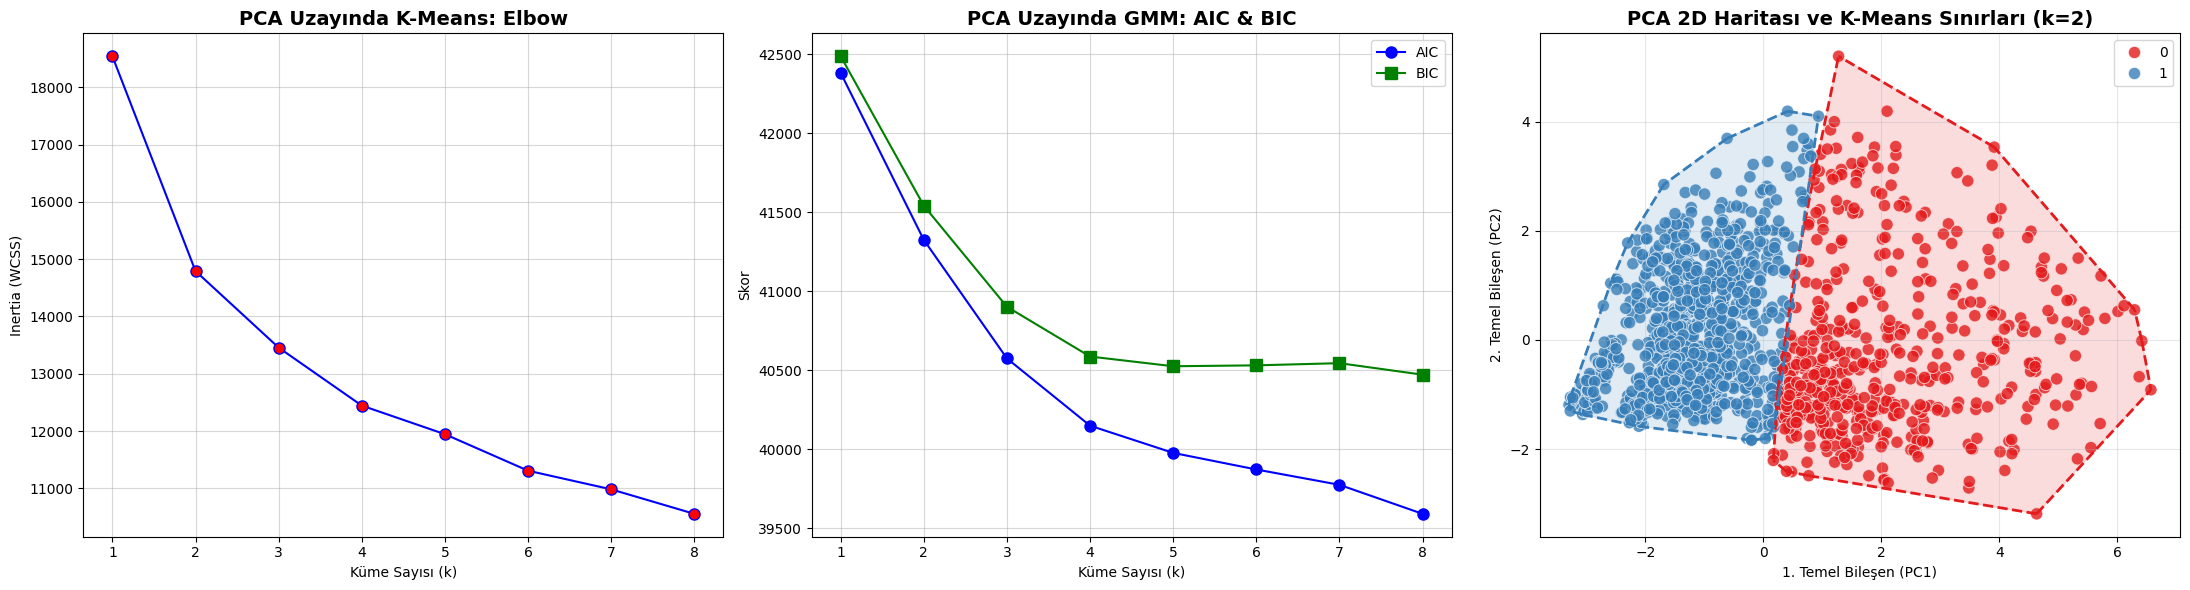

In [22]:
def plot_pca_optimal_k_and_scatter(X_num, max_k=10, pca_variance=0.90, final_k=3):
    # 1. STANDARTLAŞTIRMA VE PCA İŞLEMİ
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_num)
    
    pca = PCA(n_components=pca_variance, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    print(f"PCA Sonrası Özellik Sayısı (Varyansın %{int(pca_variance*100)}'i korundu): {X_pca.shape[1]}")

    # 2. OPTİMUM KÜME SAYISI METRİKLERİ (Elbow & AIC/BIC)
    n_components = np.arange(1, max_k + 1)
    inertia = []
    aic = []
    bic = []
    
    print("Modeller PCA uzayında eğitiliyor...")
    for k in n_components:
        km = KMeans(n_clusters=k, random_state=42, n_init='auto').fit(X_pca)
        inertia.append(km.inertia_)

        gmm = GaussianMixture(n_components=k, random_state=42, covariance_type='diag').fit(X_pca)
        aic.append(gmm.aic(X_pca))
        bic.append(gmm.bic(X_pca))
        
    # 3. GÖRSELLEŞTİRME (1 Satır, 3 Sütun)
    fig, ax = plt.subplots(1, 3, figsize=(22, 6))

    ax[0].plot(n_components, inertia, 'bo-', markerfacecolor='red', markersize=8)
    ax[0].set_title('PCA Uzayında K-Means: Elbow', fontsize=14, fontweight='bold')
    ax[0].set_xlabel('Küme Sayısı (k)')
    ax[0].set_ylabel('Inertia (WCSS)')
    ax[0].set_xticks(n_components)
    ax[0].grid(True, alpha=0.5)

    ax[1].plot(n_components, aic, label='AIC', color='blue', marker='o', markersize=8)
    ax[1].plot(n_components, bic, label='BIC', color='green', marker='s', markersize=8)
    ax[1].set_title('PCA Uzayında GMM: AIC & BIC', fontsize=14, fontweight='bold')
    ax[1].set_xlabel('Küme Sayısı (k)')
    ax[1].set_ylabel('Skor')
    ax[1].set_xticks(n_components)
    ax[1].legend()
    ax[1].grid(True, alpha=0.5)

    # --- Sağ Grafik: PCA Scatter ve K-Means Sınırları ---
    kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init='auto')
    labels_final = kmeans_final.fit_predict(X_pca)

    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_final, palette='Set1', s=80, alpha=0.8, ax=ax[2])

    colors = sns.color_palette('Set1', n_colors=final_k)
    for i in range(final_k):
        # BURASI DÜZELDİ: Sadece ilk 2 boyutu (PC1 ve PC2) veriyoruz!
        points = X_pca[labels_final == i, :2] 
        
        if len(points) >= 3:
            hull = ConvexHull(points)
            for simplex in hull.simplices:
                ax[2].plot(points[simplex, 0], points[simplex, 1], color=colors[i], lw=2, linestyle='--')
            ax[2].fill(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], alpha=0.15)

    ax[2].set_title(f'PCA 2D Haritası ve K-Means Sınırları (k={final_k})', fontsize=14, fontweight='bold')
    ax[2].set_xlabel('1. Temel Bileşen (PC1)')
    ax[2].set_ylabel('2. Temel Bileşen (PC2)')
    ax[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Fonksiyonu Çağırma
plot_pca_optimal_k_and_scatter(df_clean[num_cols], max_k=8, pca_variance=0.90, final_k=2)

In [27]:
def compare_all_models(X_num, optimal_k=2, pca_variance=0.90):
    """
    K-Means, GMM ve Hiyerarşik Kümeleme algoritmalarını hem 
    orijinal veride hem de PCA ile indirgenmiş veride çalıştırır 
    ve başarı skorlarını tek bir tabloda karşılaştırır.
    """
    # 1. STANDARTLAŞTIRMA VE PCA İŞLEMİ
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_num)
    
    pca = PCA(n_components=pca_variance, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    # 2. MODELLERİN TANIMLANMASI
    # (Hızlı çalışması için GMM'de 'diag' kullanıyoruz)
    models_orijinal = {
        "K-Means (Orijinal)": KMeans(n_clusters=optimal_k, random_state=42, n_init='auto'),
        "GMM (Orijinal)": GaussianMixture(n_components=optimal_k, random_state=42, covariance_type='diag'),
        "Hiyerarşik (Orijinal)": AgglomerativeClustering(n_clusters=optimal_k)
    }
    
    models_pca = {
        "K-Means (PCA'li)": KMeans(n_clusters=optimal_k, random_state=42, n_init='auto'),
        "GMM (PCA'li)": GaussianMixture(n_components=optimal_k, random_state=42, covariance_type='diag'),
        "Hiyerarşik (PCA'li)": AgglomerativeClustering(n_clusters=optimal_k)
    }
    
    results = []
    
    # 3. ORİJİNAL VERİDE EĞİTİM
    for name, model in models_orijinal.items():
        if "GMM" in name:
            labels = model.fit_predict(X_scaled)
        else:
            labels = model.fit(X_scaled).labels_
        
        sil_score = silhouette_score(X_scaled, labels)
        db_score = davies_bouldin_score(X_scaled, labels)
        results.append({"Model": name, "Silhouette Skoru (↑)": round(sil_score, 4), "Davies-Bouldin Skoru (↓)": round(db_score, 4)})
        
    # 4. PCA'Lİ VERİDE EĞİTİM
    for name, model in models_pca.items():
        if "GMM" in name:
            labels = model.fit_predict(X_pca)
        else:
            labels = model.fit(X_pca).labels_
        
        # PCA sonrası bile olsa adil karşılaştırma için metrikleri orijinal (X_scaled) üzerinden hesaplıyoruz!
        sil_score = silhouette_score(X_scaled, labels)
        db_score = davies_bouldin_score(X_scaled, labels)
        results.append({"Model": name, "Silhouette Skoru (↑)": round(sil_score, 4), "Davies-Bouldin Skoru (↓)": round(db_score, 4)})
        
    # 5. TABLOYU OLUŞTUR VE SIRALA
    df_results = pd.DataFrame(results).sort_values(by="Silhouette Skoru (↑)", ascending=False).reset_index(drop=True)
    
    print(f"--- KARŞILAŞTIRMA RAPORU (k={optimal_k}, PCA Varyansı=%{int(pca_variance*100)}) ---")
    return df_results

# Fonksiyonu Çağır (K-Means ve diğerleri için k=2 varsayarak çalıştırıyoruz)
karsilastirma_tablosu = compare_all_models(df_clean[num_cols], optimal_k=2, pca_variance=0.90)
display(karsilastirma_tablosu)

--- KARŞILAŞTIRMA RAPORU (k=2, PCA Varyansı=%90) ---


,Model,Silhouette Skoru (↑),Davies-Bouldin Skoru (↓)
0,K-Means (Orijinal),0.1897,2.0156
1,K-Means (PCA'li),0.1894,2.0166
2,Hiyerarşik (PCA'li),0.1731,2.1000
3,Hiyerarşik (Orijinal),0.1678,2.1537
4,GMM (Orijinal),0.1582,2.1459
5,GMM (PCA'li),0.1210,2.3358


In [31]:
# K-Prototypes için temizlenmiş orijinal verinin kopyasını alıyoruz
df_kproto = df_clean.copy()

# SADECE sayısal kolonları Standartlaştırıyoruz (Kategorikler olduğu gibi kalmalı)
scaler_kp = StandardScaler()
df_kproto[num_cols] = scaler_kp.fit_transform(df_kproto[num_cols])

# Kategorik kolonların DataFrame içindeki sıra (index) numaralarını buluyoruz
cat_cols_pos = [df_kproto.columns.get_loc(col) for col in cat_cols]

print("Karma verilerle K-Prototypes eğitiliyor...")
# İş zekası (Business Intelligence) açısından en mantıklı senaryo olan 3 Persona çıkarıyoruz
kproto = KPrototypes(n_clusters=2, init='Cao', random_state=42, n_jobs=-1)
kproto_labels = kproto.fit_predict(df_kproto.values, categorical=cat_cols_pos)

# Küme etiketlerini (yorumlaması kolay olsun diye) scale edilmemiş temiz veriye ekliyoruz
df_personas = df_clean.copy()
df_personas['Cluster'] = kproto_labels

print("\\nKümelerin Büyüklükleri:")
print(df_personas['Cluster'].value_counts().sort_index())

Karma verilerle K-Prototypes eğitiliyor...
\nKümelerin Büyüklükleri:
Cluster
0    913
1    527
Name: count, dtype: int64


In [ ]:
def evaluate_kprototypes_metrics(kproto_model, df_personas):
    """
    K-Prototypes modeli için matematiksel ve yapısal başarı metriklerini çıkarır.
    """
    # 1. Maliyet (Cost) Skoru
    cost_score = kproto_model.cost_
    
    # 2. Küme Dağılım Dengesi Hesaplama
    cluster_counts = df_personas['Cluster'].value_counts()
    cluster_ratios = df_personas['Cluster'].value_counts(normalize=True) * 100
    
    print("🏆 K-PROTOTYPES BAŞARI METRİKLERİ 🏆\n")
    print("-" * 50)
    print(f"🔹 Optimizasyon Maliyeti (Cost Score) : {cost_score:,.2f}")
    print("   *(Not: Bu skorun mutlak değeri verinin büyüklüğüne bağlıdır.")
    print("   Elbow grafiğindeki kırılım noktasında olması başarısını gösterir.)\n")
    
    print("🔹 Küme Yığılma Oranları (Balance):")
    for cluster, count in cluster_counts.items():
        ratio = cluster_ratios[cluster]
        print(f"   Küme {cluster}: {count} Kişi ( %{ratio:.1f} )")
        
    print("-" * 50)
    print("\n⚠️ Neden Silhouette Skoru Yok?")
    print("Standart Silhouette ve Davies-Bouldin metrikleri, K-Prototypes'ın kullandığı")
    print("kategorik eşleşme (Hamming) mesafesini matematiksel olarak algılayamaz.")
    print("Bu algoritmada asıl başarı ölçütü, yukarıdaki Maliyet (Cost) dengesi ve")
    print("bir önceki adımda çıkardığımız İK Personalarının iş zekası açısından tutarlılığıdır.")

# Fonksiyonu Çağır (3. Adımda eğittiğimiz kproto modeli ve df_personas ile)
evaluate_kprototypes_metrics(kproto, df_personas)

🏆 K-PROTOTYPES BAŞARI METRİKLERİ 🏆

--------------------------------------------------
🔹 Optimizasyon Maliyeti (Cost Score) : 22,052.56
   *(Not: Bu skorun mutlak değeri verinin büyüklüğüne bağlıdır.
   Elbow grafiğindeki kırılım noktasında olması başarısını gösterir.)

🔹 Küme Yığılma Oranları (Balance):
   Küme 0: 913 Kişi ( %63.4 )
   Küme 1: 527 Kişi ( %36.6 )
--------------------------------------------------

⚠️ Neden Silhouette Skoru Yok?
Standart Silhouette ve Davies-Bouldin metrikleri, K-Prototypes'ın kullandığı
kategorik eşleşme (Hamming) mesafesini matematiksel olarak algılayamaz.
Bu algoritmada asıl başarı ölçütü, yukarıdaki Maliyet (Cost) dengesi ve
bir önceki adımda çıkardığımız İK Personalarının iş zekası açısından tutarlılığıdır.


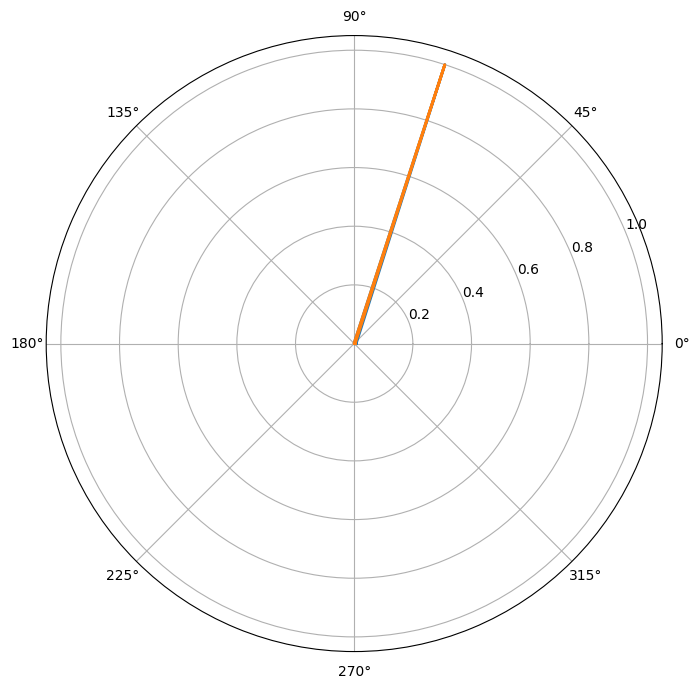

In [30]:
from math import pi

# Radar grafiğinde görmek istediğimiz en kritik 5 İK sayisal metriği
radar_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'DistanceFromHome']

# Kümelerin bu metriklerdeki ortalamalarını hesapla
cluster_means = df_personas.groupby('Cluster')[radar_cols].mean()

# Radar grafiğinin düzgün çizilebilmesi için değerleri 0 ile 1 arasına sıkıştırıyoruz (MinMax)
scaler_radar = MinMaxScaler()
normalized_means = pd.DataFrame(scaler_radar.fit_transform(cluster_means.T).T, columns=radar_cols)

# --- RADAR GRAFİĞİ ÇİZİMİ ---
categories = radar_cols
N = len(categories)

# Açıları hesapla
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1] # Daireyi kapatmak için ilk açıyı sona ekliyoruz

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

# Kümeleri döngü ile tek tek çizelim
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
persona_names = ['Persona 0', 'Persona 1', 'Persona 2']

for i in range(3):
    values = normalized_means.iloc[i].values.flatten().tolist()
    values += values[:1] # Daireyi kapat
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=persona_names[i], color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.15)

plt.xticks(angles[:-1], categories, size=11)
plt.yticks([], []) # İç çember numaralarını gizle (estetik için)
plt.title("İK Personaları Çarpraz Analizi (Radar Plot)", size=16, y=1.1, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# --- DOMİNANT KATEGORİK ÖZELLİKLERİ YAZDIRMA ---
print("\\n" + "="*50)
print(" KÜMELERİN DOMİNANT KATEGORİK/ORDİNAL PROFİLLERİ")
print("="*50)
for i in range(3):
    cluster_data = df_personas[df_personas['Cluster'] == i]
    print(f"\\n🚀 KÜME {i} ({len(cluster_data)} Kişi):")
    print(f"  • En çok çalışan Departman : {cluster_data['Department'].mode()[0]}")
    print(f"  • Ortalama İş Seviyesi     : {cluster_data['JobLevel'].mode()[0]} (1 Düşük - 5 Yüksek)")
    print(f"  • İş Tatmini Yoğunluğu     : {cluster_data['JobSatisfaction'].mode()[0]} (1 Düşük - 4 Yüksek)")
    print(f"  • Medeni Durum Çoğunluğu   : {cluster_data['MaritalStatus'].mode()[0]}")